# sFRC — global 2D resolution estimation

## Import the analysis functions

Import `sFRC` and the shared FRC comparison plot from `src`, together with the existing image-loading and optional result-export tools. All pixel sizes and reported resolutions are in **nm**.


In [1]:
from pathlib import Path
import sys
import numpy as np
import tifffile
import matplotlib.pyplot as plt

# Support notebooks launched from the repository root or demos/.
repo = Path.cwd().resolve()
if not (repo / 'src' / 'sFRC.py').is_file():
    repo = repo.parent
if not (repo / 'src' / 'sFRC.py').is_file():
    raise RuntimeError('Run this notebook from the repository root or demos/ directory.')
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
example_dir = repo / 'example_data'

from src.sFRC import sFRC
from src.utils.analysis_results import normalize_threshold
from src.utils.plotting import ResolutionPlotter
from src.utils.save_results import save_sfrc_results

## 1. Load the image and set the acquisition parameters

`single_frame=True` constructs complementary observations from the selected image. Set it to `False` when the TIFF contains at least two independently acquired frames. Supply the **original** pixel size; the algorithm accounts for its internal resampling.

Input shape: (2, 1024, 1024)


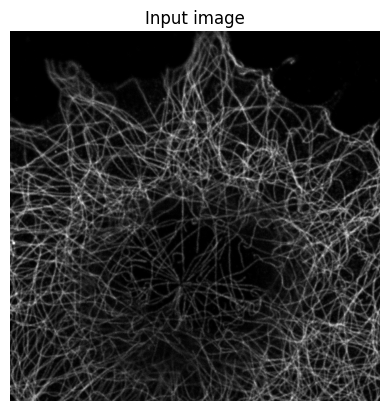

In [2]:
input_file = example_dir / 'Fig3a_Raw.tif'
if not input_file.is_file():
    raise FileNotFoundError(f'Add the TIFF file: {input_file}')
images = tifffile.imread(input_file)
pixel_size_nm = 60                 # Replace with the acquisition calibration.
single_frame = True                 # False: use an adjacent pair from a (T,Y,X) stack.

print('Input shape:', images.shape)
preview = images if images.ndim == 2 else images[0]
plt.imshow(preview, cmap='gray')
plt.title('Input image')
plt.axis('off')
plt.show()

## 2. Calculate the selected FRC result

Run one analysis with the selected settings. The next section overlays single-frame and paired-frame FRC on a **shared spatial-frequency axis** instead of opening separate figures. With a one-frame input, only the single-frame FRC can be measured.

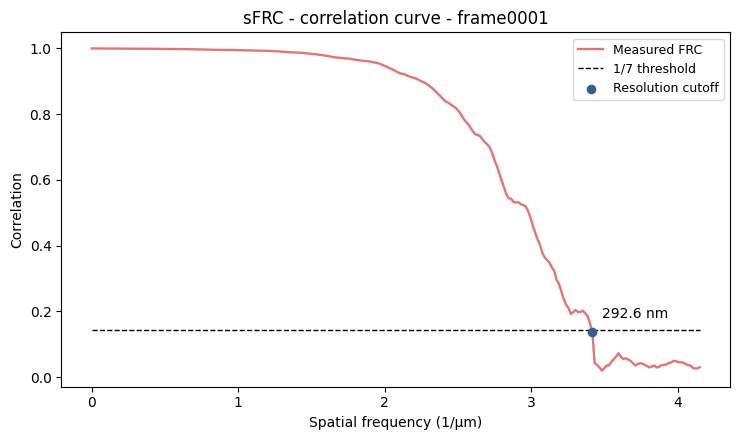

{'resolution_nm': np.float64(292.57142857142856), 'frame': 'frame0001', 'singleframe': True, 'threshold': 'fixed_threshold', 'extrapolation_triggered': False}


In [3]:
result = sFRC(images, pixel_size=pixel_size_nm, single_frame=single_frame,
              batch_processing=False, plot=True)
print(result.summary)